In [136]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

In [137]:
X = np.array([1 ,2 ,3, 4, 5])
y = np.array([3, 5, 7, 9, 11])

In [138]:
def predict(X ,w ,b):
    return w * X + b

In [139]:
def mse(y, y_pred):
    return np.mean((y-y_pred) ** 2)

In [140]:
def gradients(X, y, y_pred):
    dw = 2 * (np.mean((y_pred - y) * X))
    db = 2 * (np.mean(y_pred - y))
    return dw, db

In [150]:
def train_loop(X, y, w, b, learning_rate, steps):
    w_history, b_history = [w], [b]
    y_pred = predict(X, w, b)
    loss_history = [float(mse(y, y_pred))]

    for _ in range(steps):
        y_pred = predict(X, w, b)
        dw, db = gradients(X, y, y_pred)

        w = w - learning_rate * dw
        b = b - learning_rate * db

        y_pred = predict(X, w, b)
        loss = mse(y, y_pred)

        w_history.append(float(w))
        b_history.append(float(b))
        loss_history.append(float(loss))
    
    return w_history, b_history, loss_history

In [142]:
w_values = np.linspace(-1, 4.5, 100)
b_values = np.linspace(-2, 4 ,100)
print(w_values.shape)
print(b_values.shape)

(100,)
(100,)


In [143]:
small_w = np.array([0, 1, 2])
small_b = np.array([10, 20, 30])

small_W, small_B = np.meshgrid(small_w, small_b)

print(small_W)
print(small_B)

[[0 1 2]
 [0 1 2]
 [0 1 2]]
[[10 10 10]
 [20 20 20]
 [30 30 30]]


In [144]:
def compute_loss_surface(X, y, w_values, b_values):
    W, B = np.meshgrid(w_values, b_values)
    loss_surface = np.zeros_like(W, dtype = float)

    for i in range(W.shape[0]):
        for j in range(W.shape[1]):
            y_pred = predict(X, W[i, j], B[i, j])
            loss_surface[i, j] = mse(y, y_pred)
    return W, B, loss_surface


In [145]:
W, B, loss_surface = compute_loss_surface(X, y, w_values, b_values)

print(np.argmin(loss_surface))
print("w = ", W[50, 50])
print("b = ", B[50, 50])
print("MSE = ", loss_surface[50,50])

flat_index = np.argmin(loss_surface)
i, j = np.unravel_index(flat_index, loss_surface.shape)

print(i, j)

print("w = ", W[i, j])
print("b = ", B[i ,j])
print("MSE = ", loss_surface[i,j])

4954
w =  1.7777777777777777
b =  1.0303030303030303
MSE =  0.5037241097847153
49 54
w =  2.0
b =  0.9696969696969697
MSE =  0.0009182736455463928


In [146]:
w_history, b_history, loss_history = train_loop(X, y, w = 0, b = 0, learning_rate=0.01, steps = 600)

print(w_history[:5])
print(b_history[:5])

print(w_history[-5:])
print(b_history[-5:])

[0, 0.5, 0.8815999999999999, 1.172816, 1.39503488]
[0, 0.14, 0.2472, 0.32936, 0.39240384]
[2.015244338386162, 2.0151927978557915, 2.015141431582001, 2.0150902389756356, 2.015039219449532]
[0.9449631014235794, 0.9451491790919381, 0.9453346276387519, 0.9455194491910568, 0.9457036458686975]


In [147]:
levels= [0.002, 0.01, 0.1, 0.5, 1, 2, 5, 10, 20, 50, 100]

def plot_contour_with_path(ax, W, B, loss_surface, w_history, b_history, lr, levels):
    contours = ax.contour(W, B, loss_surface, levels = levels)
    ax.clabel(contours, inline = True, fontsize = 8)
    
    ax.plot(w_history[:150], b_history[:150], marker='o', markersize=3, linewidth=1.5, alpha=0.8, markevery = 10)
    ax.scatter(w_history[0], b_history[0], marker='s', s=80, label='start')
    ax.scatter(w_history[-1], b_history[-1], marker='x', s=80, label='end')
    ax.scatter(2, 1, marker='*', s=120, color='grey', label='true point')

    ax.set_title(f"Contour + trajektoria\nlr = {lr}")
    ax.set_xlabel("w")
    ax.set_ylabel("b")
    ax.legend(fontsize=8)

In [148]:
def plot_loss_history(ax, loss_history, lr):
    ax.plot(loss_history, linewidth=2)
    ax.set_title(f"MSE w czasie\nlr = {lr}")
    ax.set_xlabel("Training step")
    ax.set_ylabel("MSE")
    ax.set_yscale("log")

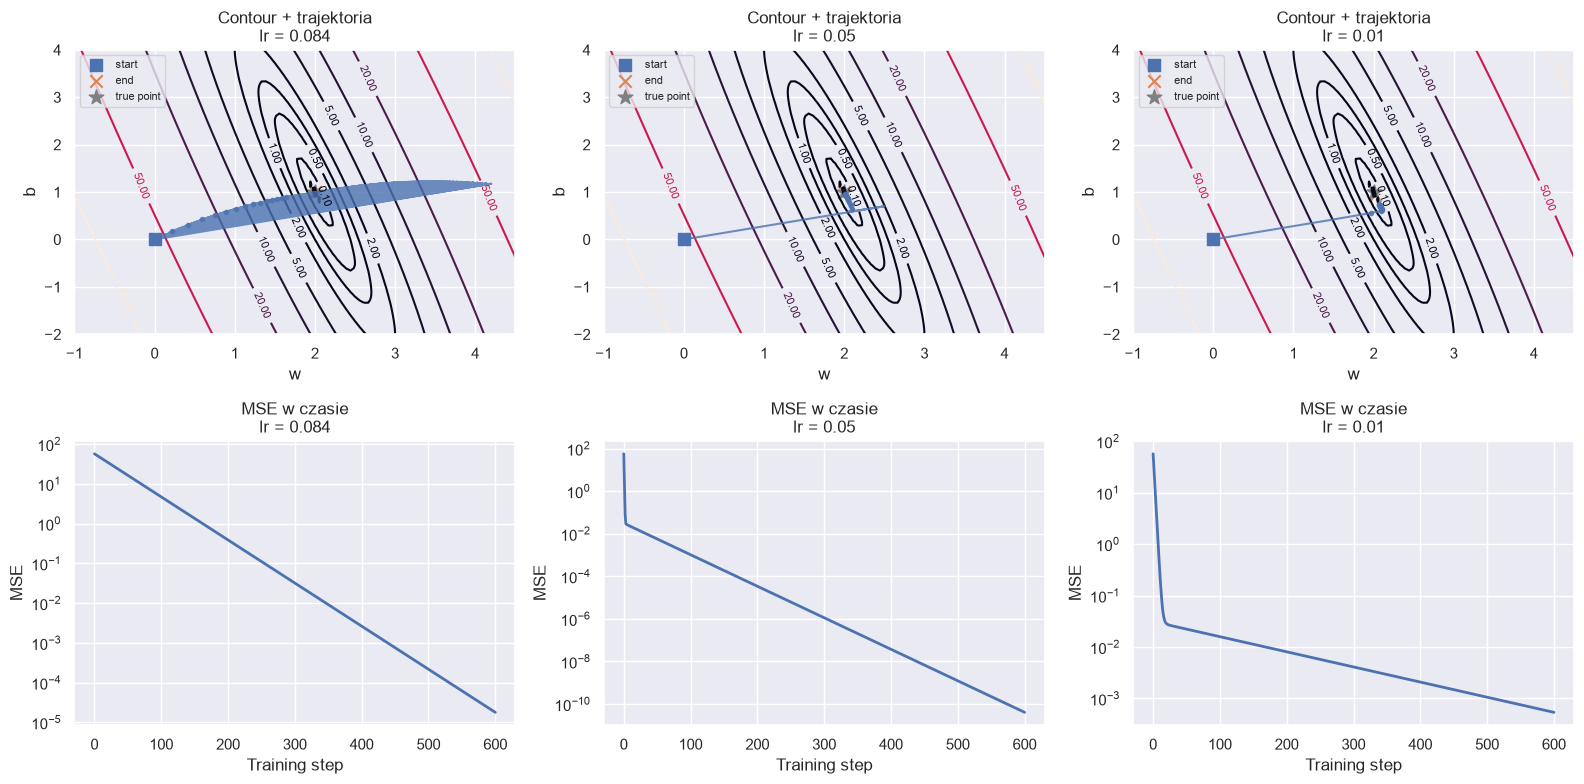

In [ ]:
W, B, loss_surface = compute_loss_surface(X, y, w_values, b_values)

learning_rates = [0.084, 0.05, 0.01]
levels = [0.002, 0.01, 0.1, 0.5, 1, 2, 5, 10, 20, 50, 100]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for col, lr in enumerate(learning_rates):
    w_history, b_history, loss_history = train_loop(X, y, w=0, b=0, learning_rate=lr, steps=600)

    plot_contour_with_path(axes[0, col], W, B, loss_surface, w_history, b_history, lr, levels)

    plot_loss_history(axes[1, col], loss_history, lr)

plt.tight_layout()
plt.show()

print(len(w_history))
print(len(b_history))
print(len(loss_history))